# Power analysis GWAS synthetic data with additive effect

In [44]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats

In [45]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)
humans

,sample,sample.1,pop,super_pop,gender
0,HG00096,HG00096,GBR,EUR,male
1,HG00097,HG00097,GBR,EUR,female
2,HG00099,HG00099,GBR,EUR,female
3,HG00100,HG00100,GBR,EUR,female
4,HG00101,HG00101,GBR,EUR,male
...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female
2500,NA21141,NA21141,GIH,SAS,female
2501,NA21142,NA21142,GIH,SAS,female
2502,NA21143,NA21143,GIH,SAS,female


In [46]:
os.listdir('./data/genotype')

['0_0_115_0_maf_0.01_0.01.pkl',
 '21_9_120_21_maf_0.024_0.025.pkl',
 '124_0_118_124_maf_0.4_0.41.pkl',
 '107_3_80_107_maf_0.3_0.31.pkl',
 '48_9_120_48_maf_0.068_0.07.pkl',
 '42_9_80_42_maf_0.055_0.057.pkl',
 '39_9_103_39_maf_0.05_0.051.pkl',
 '87_0_110_87_maf_0.2_0.2.pkl',
 '26_9_120_26_maf_0.03_0.031.pkl',
 '16_9_92_16_maf_0.02_0.021.pkl',
 '33_9_89_33_maf_0.04_0.041.pkl',
 '57_7_120_57_maf_0.091_0.094.pkl',
 '44_9_114_44_maf_0.059_0.061.pkl',
 '36_9_80_36_maf_0.044_0.046.pkl',
 '53_1_116_53_maf_0.08_0.083.pkl',
 '138_9_80_138_maf_0.49_0.49.pkl',
 '75_4_91_75_maf_0.15_0.15.pkl',
 '30_9_80_30_maf_0.035_0.037.pkl',
 '60_2_120_60_maf_0.1_0.1.pkl',
 '8_9_120_8_maf_0.014_0.015.pkl',
 '97_4_80_97_maf_0.25_0.25.pkl']

In [47]:
#wanted_maf = '0.01_0.01'
#wanted_maf = '0.024_0.025'
#wanted_maf = '0.048_0.05'
#wanted_maf = '0.49_0.49'
wanted_maf = '0.1_0.1'
#wanted_maf = '0.25_0.25'

In [48]:
snps = [f for f in os.listdir('./data/genotype') if f.split("_maf_")[1].split('.pkl')[0] == wanted_maf]
for snp in snps:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    path_snp = f"./data/genotype/{snp}"
    print(path_snp)

./data/genotype/60_2_120_60_maf_0.1_0.1.pkl


In [49]:
geno = pd.read_pickle(path_snp)
i = 0

In [50]:
geno[geno.columns[i]].value_counts()
num_maj = geno[geno.columns[i]].value_counts()[1]
num_het = geno[geno.columns[i]].value_counts()[0]
try:
    num_min = geno[geno.columns[i]].value_counts()[-1]
except Exception as e:
    num_min = 0
total_humans = num_maj + num_het + num_min

In [51]:
maf = (num_min*2 + num_het)/(total_humans*2)
maf

0.10263578274760383

In [52]:
mean_min_H0 = 0
mean_het_H0 = 0
mean_maj_H0 = 0

In [53]:
true_mean = 160
true_effect = 5
true_sd = 40

In [54]:
mean_min = true_mean - true_effect
mean_het = true_mean
mean_maj = true_mean + true_effect
sigma_min = true_sd
sigma_het = true_sd
sigma_maj = true_sd
pheno = []
for var in list(geno[geno.columns[i]]):
    if var == 1:
        pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
    elif var == 0:
        pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
    else:
        pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[i]]), "pheno": pheno})

In [55]:
df_pheno

,geno,pheno
0,1,122.743498
1,1,132.953055
2,1,177.375796
3,1,162.491465
4,1,143.304417
...,...,...
2499,0,168.793583
2500,1,195.871866
2501,0,157.982616
2502,1,170.231411


<AxesSubplot:xlabel='geno', ylabel='pheno'>

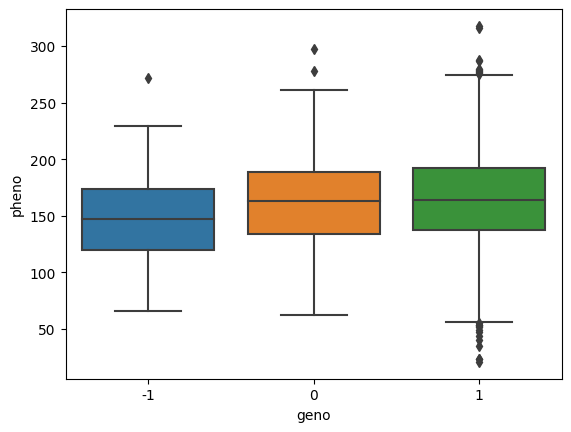

In [56]:
sns.boxplot(data=df_pheno, x="geno", y="pheno")

In [57]:
def standy(pandasdf):
    print(stats.tstd(pandasdf))
    return (pandasdf - pandasdf.mean())/stats.tstd(pandasdf)

In [58]:
X = df_pheno[['geno']]
y = df_pheno[['pheno']]

In [59]:
#y = standy(df_pheno[['pheno']])
#X = standy(df_pheno[['geno']])
#df_pheno['std_geno'] = X
#df_pheno['std_pheno'] = y

In [60]:
df_pheno

,geno,pheno
0,1,122.743498
1,1,132.953055
2,1,177.375796
3,1,162.491465
4,1,143.304417
...,...,...
2499,0,168.793583
2500,1,195.871866
2501,0,157.982616
2502,1,170.231411


In [61]:
reg = LinearRegression().fit(X, y)

In [62]:
reg.score(X, y)

0.0037666471383115407

In [63]:
estimated_effect = reg.coef_[0][0]
estimated_effect

5.224400832699499

In [64]:
estimated_intercept = reg.intercept_[0]
estimated_intercept

159.53604267668362

In [65]:
def find_lin_reg(X):
    y = reg.coef_[0][0]*X + reg.intercept_[0]
    return y

In [66]:
find_lin_reg(1)

164.76044350938312

In [67]:
estimated_effect

5.224400832699499

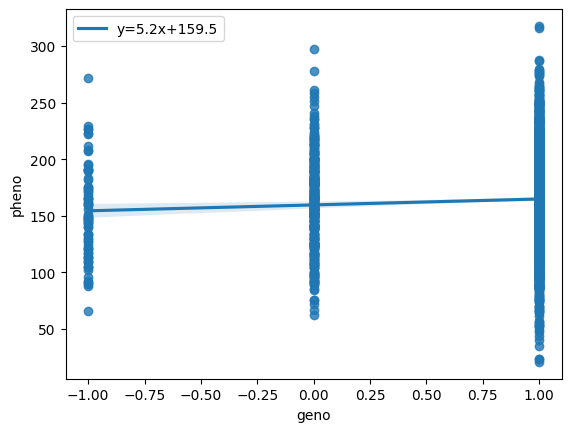

In [68]:
# use line_kws to set line label for legend
ax = sns.regplot(x="geno", y="pheno", data=df_pheno, 
 line_kws={'label':"y={0:.1f}x+{1:.1f}".format(estimated_effect,estimated_intercept)})

# plot legend
ax.legend()

plt.show()

In [69]:
N = len(X)
p = len(X.columns) + 1

X_with_intercept = np.empty(shape=(N, p), dtype=float)
X_with_intercept[:, 0] = 1
X_with_intercept[:, 1:p] = X.values

params = np.append(reg.intercept_,reg.coef_)
predictions = reg.predict(X)
new_y = (y-predictions)**2
newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))

var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
sd_b = np.sqrt(var_b)
ts_b = params/ sd_b

print(f"var = {var_b}")
print(f"sd = {sd_b}")
print(f"t_square = {ts_b}")
p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

residuals = y - predictions
residual_sum_of_squares = residuals.T @ residuals
sigma_squared_hat = residual_sum_of_squares['pheno'].pheno / (N - p)
var_beta_hat = np.linalg.inv(X_with_intercept.T @ X_with_intercept) * sigma_squared_hat

SE = []
for p_ in range(p):
    standard_error = var_beta_hat[p_, p_] ** 0.5
    SE.append(standard_error)
    print(f"SE(beta_hat[{p_}]): {standard_error}")

sd_b = np.round(sd_b,3)
ts_b = np.round(ts_b,3)
params = np.round(params,4)

var = [2.47970351 2.88530557]
sd = [1.57470744 1.69861873]
t_square = [101.31154454   3.07567599]
SE(beta_hat[0]): 1.5747074373328456
SE(beta_hat[1]): 1.698618725561634


In [70]:
p_values

[0.0, 0.002122967268181064]

# Power

In [71]:
total_humans

2504

In [72]:
maf

0.10263578274760383

In [73]:
number_of_tests = 5000

In [74]:
alt = estimated_effect
alt

5.224400832699499

In [75]:
X

,geno
0,1
1,1
2,1
3,1
4,1
...,...
2499,0
2500,1
2501,0
2502,1


## create random phenotype with no link to the genotype

In [76]:
mean_min = true_mean
mean_het = true_mean
mean_maj = true_mean
sigma_min = true_sd
sigma_het = true_sd
sigma_maj = true_sd
pheno = []
for var in list(geno[geno.columns[i]]):
    if var == 1:
        pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
    elif var == 0:
        pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
    else:
        pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
df_pheno['pheno_null'] = pheno

In [77]:
df_pheno

,geno,pheno,pheno_null
0,1,122.743498,168.306649
1,1,132.953055,168.110054
2,1,177.375796,177.374557
3,1,162.491465,179.753865
4,1,143.304417,192.655227
...,...,...,...
2499,0,168.793583,175.332557
2500,1,195.871866,176.206046
2501,0,157.982616,225.005178
2502,1,170.231411,165.901403


In [78]:
# SE under nul hypothesis
X = df_pheno[['geno']]
y = df_pheno[['pheno_null']]
reg = LinearRegression().fit(X, y)

In [79]:
N = len(X)
p = len(X.columns) + 1

X_with_intercept = np.empty(shape=(N, p), dtype=float)
X_with_intercept[:, 0] = 1
X_with_intercept[:, 1:p] = X.values

params = np.append(reg.intercept_,reg.coef_)
predictions = reg.predict(X)
new_y = (y-predictions)**2
newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
MSE = (sum(list(new_y['pheno_null'])))/(len(newX)-len(newX.columns))

var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
sd_b = np.sqrt(var_b)
ts_b = params/ sd_b
print(f"var = {var_b}")
print(f"sd = {sd_b}")
print(f"t_square = {ts_b}")

p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

residuals = y - predictions
residual_sum_of_squares = residuals.T @ residuals
sigma_squared_hat = residual_sum_of_squares['pheno_null'].pheno_null / (N - p)
var_beta_hat = np.linalg.inv(X_with_intercept.T @ X_with_intercept) * sigma_squared_hat
SE = []
for p_ in range(p):
    standard_error = var_beta_hat[p_, p_] ** 0.5
    SE.append(standard_error)
    print(f"SE(beta_hat[{p_}]): {standard_error}")

sd_b = np.round(sd_b,3)
ts_b = np.round(ts_b,3)
params = np.round(params,4)

var = [2.40600908 2.79955704]
sd = [1.55113155 1.67318769]
t_square = [105.97922434  -2.63887827]
SE(beta_hat[0]): 1.5511315497960811
SE(beta_hat[1]): 1.6731876879655254


In [80]:
SE[1]

1.6731876879655254

In [81]:
distribution_nul = np.random.normal(0, SE[1], 5000)
distribution_alt = np.random.normal(estimated_effect, SE[1], 5000)
labels = ['nul hypothesis']*len(distribution_nul) + ['alternate hypothesis'] * len(distribution_alt)
dis = pd.DataFrame(data={"Z": list(distribution_nul)+list(distribution_alt), 'labels': labels})

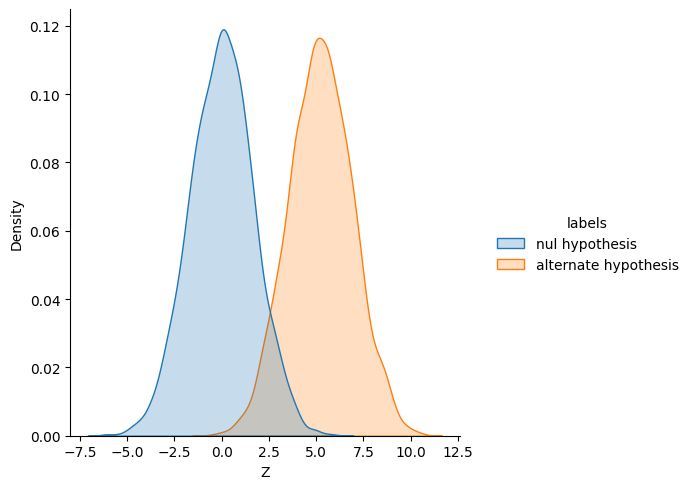

In [82]:
sns.displot(dis, x="Z", hue='labels',kind="kde",fill=True)

In [83]:
distribution_nul = np.random.normal(0, SE[1], 5000)**2
distribution_alt = np.random.normal(estimated_effect, SE[1], 5000)**2
labels = ['nul hypothesis']*len(distribution_nul) + ['alternate hypothesis'] * len(distribution_alt)
dis = pd.DataFrame(data={"Z2": list(distribution_nul)+list(distribution_alt), 'labels': labels})

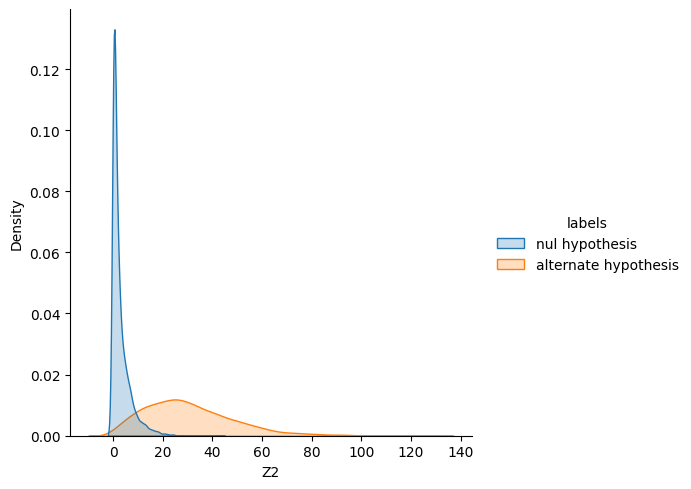

In [84]:
sns.displot(dis, x="Z2", hue='labels',kind="kde",fill=True)

In [85]:
stats.chi2.ppf(0.99, df=1)

6.6348966010212145